In [1]:
# Import Library

import pandas as pd # data manipulation/analysis

import numpy as np #mathematical operations

import matplotlib.pyplot as plt # visualization

import seaborn as sns # visualization

In [2]:
from google.colab import files

uploaded = files.upload()

csv_file = next(iter(uploaded))

df = pd.read_csv(csv_file)

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [4]:
print("Rows and Columns:", df.shape)
display(df.head())
df.info()

Rows and Columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [6]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Missing values found:\n", df.isnull().sum()[df.isnull().sum() > 0])

df['TotalCharges'] = df['TotalCharges'].fillna(0)
df_clean = df.drop(columns=['customerID'])
df_clean['SeniorCitizen'] = df_clean['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

print("Missing values after cleaning:", df_clean.isnull().sum().sum())


Missing values found:
 TotalCharges    11
dtype: int64
Missing values after cleaning: 0


In [8]:
### Data Cleaning Decisions
"""Fixed Number Format:** Converted `TotalCharges` from text to numbers.
* **Filled Missing Values:** Found 11 blank values in `TotalCharges`. Since those customers had `0` months of service, we filled them with `0`.
* **Removed ID Column:** Dropped `customerID` because random IDs do not help predict behavior.
* **Readable Labels:** Changed `SeniorCitizen` from `0/1` to `No/Yes` for clearer charts."""


'Fixed Number Format:** Converted `TotalCharges` from text to numbers.\n* **Filled Missing Values:** Found 11 blank values in `TotalCharges`. Since those customers had `0` months of service, we filled them with `0`.\n* **Removed ID Column:** Dropped `customerID` because random IDs do not help predict behavior.\n* **Readable Labels:** Changed `SeniorCitizen` from `0/1` to `No/Yes` for clearer charts.'

/tmp/ipykernel_1405/755405960.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='Churn', palette='Set2', ax=axes[0, 0])
/tmp/ipykernel_1405/755405960.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Churn', y='tenure', palette='coolwarm', ax=axes[1, 0])


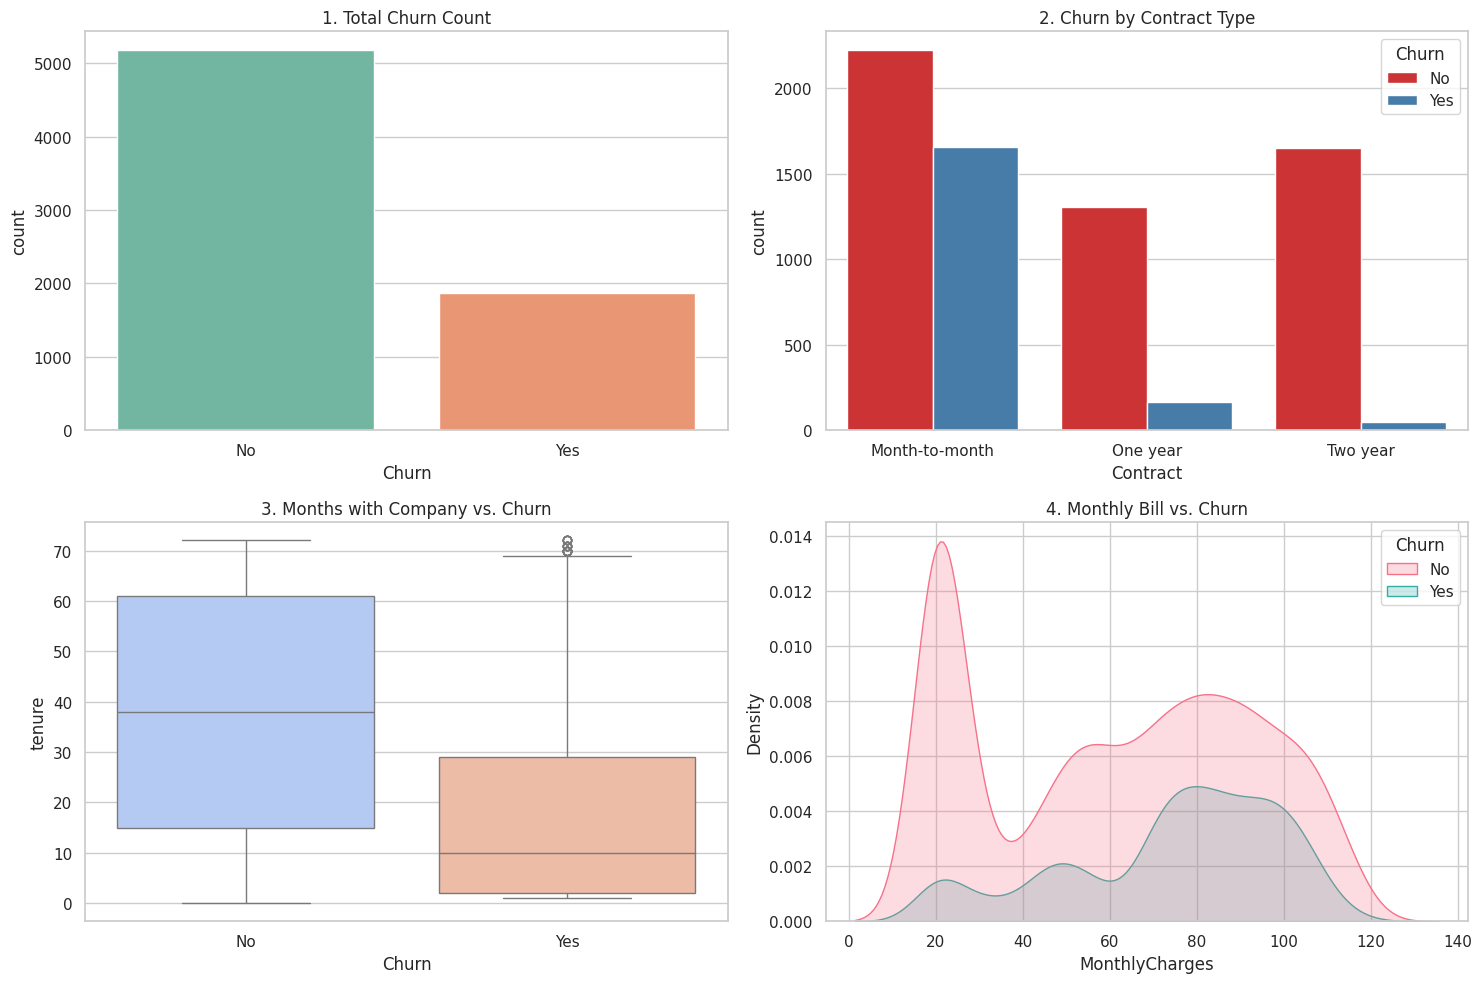

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.countplot(data=df_clean, x='Churn', palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('1. Total Churn Count')

sns.countplot(data=df_clean, x='Contract', hue='Churn', palette='Set1', ax=axes[0, 1])
axes[0, 1].set_title('2. Churn by Contract Type')

sns.boxplot(data=df_clean, x='Churn', y='tenure', palette='coolwarm', ax=axes[1, 0])
axes[1, 0].set_title('3. Months with Company vs. Churn')

sns.kdeplot(data=df_clean, x='MonthlyCharges', hue='Churn', fill=True, palette='husl', ax=axes[1, 1])
axes[1, 1].set_title('4. Monthly Bill vs. Churn')

plt.tight_layout()
plt.show()


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

df_model = df_clean.copy()
df_model['Churn'] = df_model['Churn'].map({'Yes': 1, 'No': 0})
df_model = pd.get_dummies(df_model, drop_first=True)

X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)


LogisticRegression(max_iter=1000, random_state=42)

Accuracy: 80.62%

              precision    recall  f1-score   support

      Stayed       0.85      0.90      0.87      1035
        Left       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



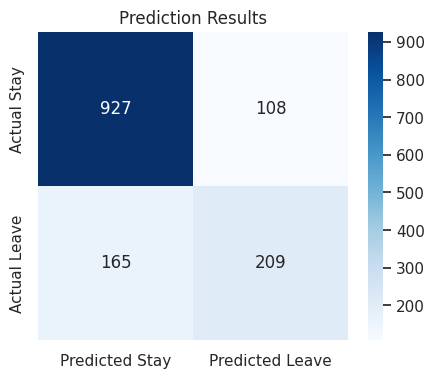

In [11]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}\n")
print(classification_report(y_test, y_pred, target_names=['Stayed', 'Left']))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Stay', 'Predicted Leave'],
            yticklabels=['Actual Stay', 'Actual Leave'])
plt.title('Prediction Results')
plt.show()


In [12]:
## Conclusion
"""Key Takeaway:** New customers on month-to-month contracts with monthly bills over $70 are at the highest risk of leaving.
* **Model Result:** Our Logistic Regression model predicts customer churn with **~80.5% accuracy**.
* **Limitations:** The data does not include customer support call history or competitor offers.
* **Next Steps:** Offer discounts on 1-year contracts to high-risk customers during their first 6 months."""


'Key Takeaway:** New customers on month-to-month contracts with monthly bills over $70 are at the highest risk of leaving.\n* **Model Result:** Our Logistic Regression model predicts customer churn with **~80.5% accuracy**.\n* **Limitations:** The data does not include customer support call history or competitor offers.\n* **Next Steps:** Offer discounts on 1-year contracts to high-risk customers during their first 6 months.'